In [1]:
print("test")

test


In [2]:
# Import necessary libraries for building and training the model
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# Initialize PyTorch and check for CUDA availability
print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.14.1+cu130
Device : cpu


In [4]:
# Load the MNIST dataset and create data loaders for training and testing
# Define a transformation to convert the images to tensors
transform = transforms.ToTensor()

# Load the MNIST dataset for training and testing
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)
# The MNIST dataset is a collection of handwritten digits commonly used for training various image processing systems. It consists of 60,000 training images and 10,000 testing images, each of size 28x28 pixels. The dataset is widely used in machine learning and computer vision research for tasks such as image classification and generative modeling.
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Create data loaders for training and testing
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)
# Print the number of samples in the training and testing datasets
print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

Train : 60000
Test  : 10000


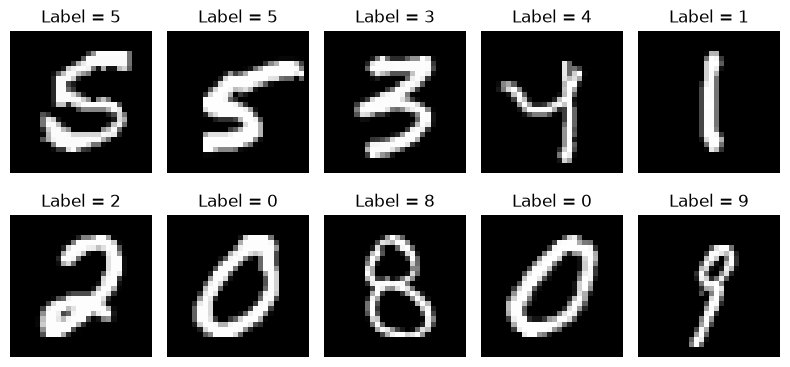

In [5]:
# Visualize some samples from the training dataset

images, labels = next(iter(train_loader))
# Display the first 10 images and their corresponding labels
fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Define a simple feedforward neural network for classifying MNIST digits
class Classifier(nn.Module):
    # Initialize the network layers
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    # Define the forward pass of the network
    def forward(self, x):
        return self.net(x)
# Instantiate the classifier and move it to the appropriate device (CPU or GPU)
classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [7]:
# Define the loss function and optimizer for training the classifier
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [8]:
# Define a function to train the classifier for a specified number of epochs
# C
def train_classifier(model, loader, epochs=3):
    model.train()
    # Condition pour vérifier si le modèle est en mode entraînement
    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )
# Train the classifier for 3 epochs using the training data loader
train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4108
Epoch 2/3 - Loss = 0.1940
Epoch 3/3 - Loss = 0.1416


In [9]:
# Define a function to evaluate the classifier's accuracy on the test dataset
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0
    # Condition pour vérifier si le modèle est en mode évaluation
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device) # Move the input data and labels to the appropriate device (CPU or GPU)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item() # Increment the count of correct predictions
            total += y.size(0)
    # Return the accuracy as the ratio of correct predictions to total samples
    return correct / total
# Evaluate the classifier on the test dataset and print the accuracy
accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.22%


### Une autre façon de verifier le model

In [10]:
# Evaluate the classifier's accuracy on the test dataset
from torcheval.metrics import MulticlassAccuracy
# Define a function to evaluate the classifier's accuracy on the test dataset
@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()

# Evaluate the classifier on the test dataset and print the accuracy
accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

/home/superrama/model_generatifs/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Accuracy = 96.22%


# Partie II - Autoencodeur

## 2-1 Idée générale

In [11]:
# Define a simple autoencoder model for dimensionality reduction and reconstruction of MNIST images
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        
        # Define the encoder and decoder networks for the autoencoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        # Define the decoder network for reconstructing images from the latent space
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    # Define the encoding function that maps input images to the latent space
    def encode(self, x):
        return self.encoder(x)
    # Define the decoding function that reconstructs images from the latent space
    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)
    # Define the forward pass of the autoencoder, which encodes the input and then decodes it back to the original space
    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

# Instantiate the autoencoder with a latent dimension of 2 and move it to the appropriate device (CPU or GPU)
ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

## 2-2 Loss de reconstruction

In [12]:
# Define the loss function and optimizer for training the autoencoder
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
# Define a function to train the autoencoder for a specified number of epochs
def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        # Loop through the training data loader and perform forward and backward passes to update the model parameters
        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )
# Train the autoencoder for 5 epochs using the training data loader
train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0658
Epoch 2/5 - Loss = 0.0526
Epoch 3/5 - Loss = 0.0508
Epoch 4/5 - Loss = 0.0491
Epoch 5/5 - Loss = 0.0473
